# Caracterización de Punto de Operación (.OP) y Respuesta AC de la OTA (Sky130)
---
Este notebook realiza la caracterización del Amplificador Operacional de Transconductancia (**OTA**) definido en `OTA_tb.sch`:

1. **Análisis en Frecuencia (Respuesta AC):**
   - Extracción de **Ganancia DC ($A_{v0}$)**, **Ancho de Banda a -3dB ($f_{-3dB}$)**, **Frecuencia de Ganancia Unitaria ($GBW$)** y **Margen de Fase ($PM$)**.
   - Diagrama de Bode Interactivo (Magnitud y Fase) con `plotly.graph_objects`.

2. **Tabla de Punto de Operación (.OP) y Verificación de Región:**
   - Extracción de parámetros de polarización y pequeña señal para los 8 transistores del OTA (`Mnr`, `Mpr`, `Mo`, `Mn`, `Mp`, `Mr`, `Mrc1`, `Mc2`):
     - Corriente de Drenador ($I_D$), Transconductancia ($g_m$), Conductancia de Drenador ($g_{ds}$), Resistencia de Salida ($r_o$), Ganancia Intrínseca ($g_m r_o$).
     - Tensiones de Polarización: $|V_{GS}|$, $|V_{DS}|$, $|V_{th}|$, $|V_{dsat}|$.
     - **Margen de Saturación:** $|V_{DS}| - |V_{dsat}|$ (Permite verificar si $|V_{DS}| \ge |V_{dsat}|$).
     - **Región de Operación:** Clasificación explícita en **Saturación**, **Triodo** o **Débil Inversión (Weak Inversion)**.


=== RESULTADOS DE CARACTERIZACIÓN AC ===
Ganancia en DC (Av0):           63.34 dB (1468.86 V/V)
Frecuencia de Corte (-3dB):    6309.57 kHz
Ancho de Banda GBW (0 dB):     794.33 MHz
Margen de Fase (PM):           -72.18°


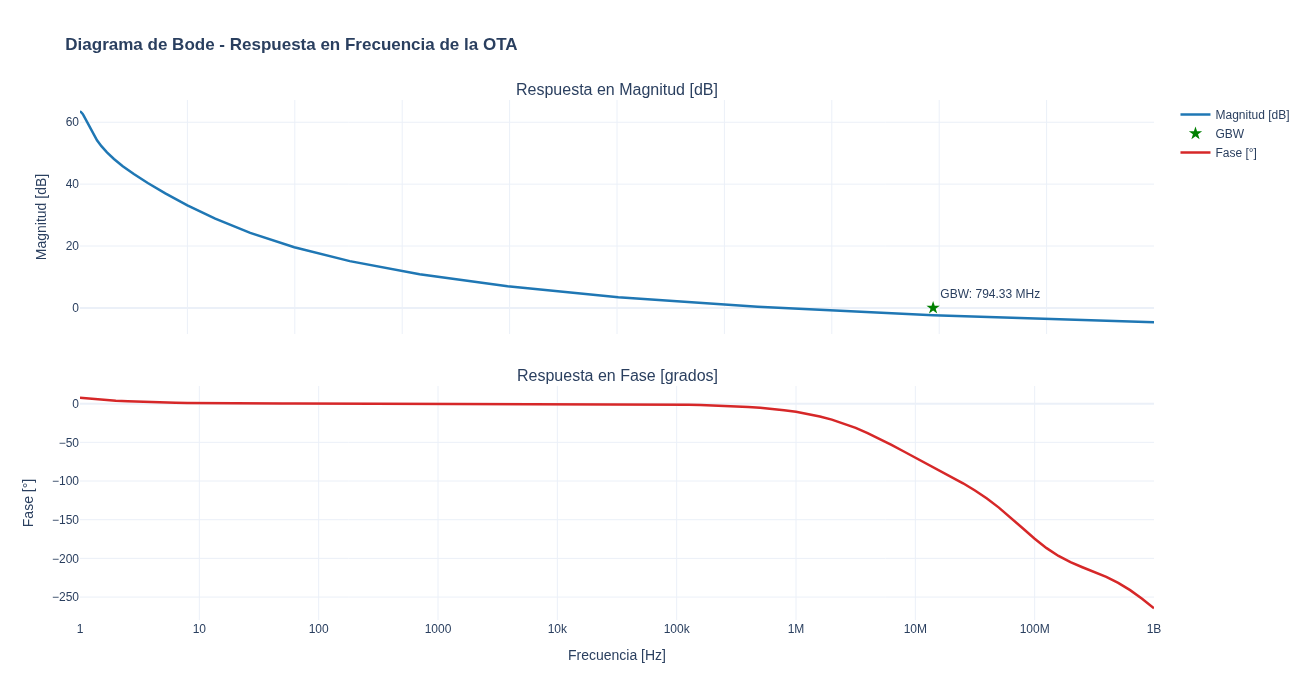

In [1]:
# ==============================================================================
# Encabezado: Simulación AC y Generación de Diagrama de Bode
# Descripción: Ejecuta la simulación AC en NGspice, extrae métricas de ganancia,
#              ancho de banda y margen de fase, y grafica el diagrama de Bode.
# ==============================================================================

import subprocess
import os
import numpy as np
np.complex_ = complex  # Parche de compatibilidad para spyci con NumPy 2.0
from spyci import spyci
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# ── 1. Carga de Datos de Simulación AC con spyci ─────────────────────────────
raw_ac_file = "../xschem/OTA_ac.raw"
if not os.path.exists(raw_ac_file):
    raw_ac_file = "/foss/designs/LDO-sky130/xschem/OTA_ac.raw"

ac_data = spyci.load_raw(raw_ac_file)
raw_ac_vals = ac_data['values']

freq = np.real(raw_ac_vals['frequency'])
vo_complex = raw_ac_vals['v(vo)']

mag_db = 20 * np.log10(np.abs(vo_complex))
phase_deg = np.angle(vo_complex, deg=True)
phase_deg = np.unwrap(np.radians(phase_deg)) * (180.0 / np.pi)

# ── 2. Cálculo de Métricas de Desempeño AC ───────────────────────────────────
av0_db = mag_db[0]
av0_lin = 10**(av0_db / 20.0)

idx_3db = np.where(mag_db <= (av0_db - 3.0))[0]
f_3db = freq[idx_3db[0]] if len(idx_3db) > 0 else np.nan

idx_gbw = np.where(mag_db <= 0.0)[0]
if len(idx_gbw) > 0:
    f_gbw = freq[idx_gbw[0]]
    pm = 180.0 + phase_deg[idx_gbw[0]]
else:
    f_gbw = np.nan
    pm = np.nan

print("=== RESULTADOS DE CARACTERIZACIÓN AC ===")
print(f"Ganancia en DC (Av0):           {av0_db:.2f} dB ({av0_lin:.2f} V/V)")
print(f"Frecuencia de Corte (-3dB):    {f_3db/1e3:.2f} kHz")
print(f"Ancho de Banda GBW (0 dB):     {f_gbw/1e6:.2f} MHz")
print(f"Margen de Fase (PM):           {pm:.2f}°")

# ── 3. Generación de Diagrama de Bode con Plotly ─────────────────────────────
fig = make_subplots(rows=2, cols=1, shared_xaxes=True,
                    vertical_spacing=0.1,
                    subplot_titles=("Respuesta en Magnitud [dB]", "Respuesta en Fase [grados]"))

fig.add_trace(go.Scatter(x=freq, y=mag_db, mode='lines', name='Magnitud [dB]',
                         line=dict(color='#1f77b4', width=2.5)), row=1, col=1)

if not np.isnan(f_gbw):
    fig.add_trace(go.Scatter(x=[f_gbw], y=[0], mode='markers+text', name='GBW',
                             text=[f'GBW: {f_gbw/1e6:.2f} MHz'], textposition='top right',
                             marker=dict(size=10, color='green', symbol='star')), row=1, col=1)

fig.add_trace(go.Scatter(x=freq, y=phase_deg, mode='lines', name='Fase [°]',
                         line=dict(color='#d62728', width=2.5)), row=2, col=1)

fig.update_xaxes(type="log", title_text="Frecuencia [Hz]", row=2, col=1)
fig.update_yaxes(title_text="Magnitud [dB]", row=1, col=1)
fig.update_yaxes(title_text="Fase [°]", row=2, col=1)

fig.update_layout(height=700, title_text="<b>Diagrama de Bode - Respuesta en Frecuencia de la OTA</b>",
                  template="plotly_white", showlegend=True)
fig.show()

In [2]:
# ==============================================================================
# Encabezado: Extracción de Tabla de Punto de Operación (.OP)
# Descripción: Extrae los parámetros de polarización (VGS, VDS, Vth, Vdsat, 
#              VDS - Vdsat), pequeña señal (gm, gds, ro, gm*ro) y clasifica 
#              la región de operación (Saturación, Triodo, Débil Inversión) 
#              para todos los 8 transistores de la OTA.
# ==============================================================================

import pandas as pd
import numpy as np

raw_op_file = "../xschem/OTA_op.raw"
if not os.path.exists(raw_op_file):
    raw_op_file = "/foss/designs/LDO-sky130/xschem/OTA_op.raw"

op_data = spyci.load_raw(raw_op_file)
raw_vals = op_data['values']

transistores_ota = [
    ('Mnr (PMOS Mirror L)', 'pfet_01v8', 'xmnr'),
    ('Mpr (PMOS Mirror R)', 'pfet_01v8', 'xmpr'),
    ('Mo  (PMOS Output)',   'pfet_01v8', 'xmo'),
    ('Mn  (NMOS Diff L)',   'nfet_01v8', 'xmn'),
    ('Mp  (NMOS Diff R)',   'nfet_01v8', 'xmp'),
    ('Mr  (NMOS Ref)',      'nfet_01v8', 'xmr'),
    ('Mrc1(NMOS Tail)',     'nfet_01v8', 'xmrc1'),
    ('Mc2 (NMOS Output)',   'nfet_01v8', 'xmc2'),
]

filas_op = []

for titulo, modelo, inst in transistores_ota:
    gm_key    = f'@m.x1.{inst}.msky130_fd_pr__{modelo}[gm]'
    gds_key   = f'@m.x1.{inst}.msky130_fd_pr__{modelo}[gds]'
    id_key    = f'i(@m.x1.{inst}.msky130_fd_pr__{modelo}[id])'
    vgs_key   = f'v(@m.x1.{inst}.msky130_fd_pr__{modelo}[vgs])'
    vds_key   = f'v(@m.x1.{inst}.msky130_fd_pr__{modelo}[vds])'
    vth_key   = f'v(@m.x1.{inst}.msky130_fd_pr__{modelo}[vth])'
    vdsat_key = f'v(@m.x1.{inst}.msky130_fd_pr__{modelo}[vdsat])'
    
    gm     = float(np.abs(raw_vals[gm_key][0])) * 1e6      # uS
    gds    = float(np.abs(raw_vals[gds_key][0])) * 1e6     # uS
    id_val = float(np.abs(raw_vals[id_key][0])) * 1e6      # uA
    vgs    = float(np.abs(raw_vals[vgs_key][0]))           # V
    vds    = float(np.abs(raw_vals[vds_key][0]))           # V
    vth    = float(np.abs(raw_vals[vth_key][0]))           # V
    vdsat  = float(np.abs(raw_vals[vdsat_key][0]))         # V
    
    vds_margen = vds - vdsat  # Margen de saturación (VDS - Vdsat)
    ro = (1.0 / (gds * 1e-6)) / 1e3 if gds > 0 else np.nan # kOhm
    gm_ro = (gm * 1e-6) * (ro * 1e3) if not np.isnan(ro) else np.nan
    
    if vgs < vth:
        region = 'Débil Inversión'
    elif vds >= vdsat:
        region = 'Saturación'
    else:
        region = 'Triodo'
        
    filas_op.append({
        'Transistor': titulo,
        'Id [uA]': round(id_val, 2),
        'gm [uS]': round(gm, 2),
        'gds [uS]': round(gds, 2),
        'ro [kOhm]': round(ro, 2),
        'gm*ro [V/V]': round(gm_ro, 2),
        '|VGS| [V]': round(vgs, 3),
        '|VDS| [V]': round(vds, 3),
        '|Vth| [V]': round(vth, 3),
        '|Vdsat| [V]': round(vdsat, 3),
        '|VDS|-|Vdsat| [V]': round(vds_margen, 3),
        'Región de Operación': region
    })

df_op = pd.DataFrame(filas_op)
print("=== TABLA DE PUNTO DE OPERACIÓN (.OP) Y REGIÓN DE OPERACIÓN DE LA OTA ===")
display(df_op)

=== TABLA DE PUNTO DE OPERACIÓN (.OP) Y REGIÓN DE OPERACIÓN DE LA OTA ===


,Transistor,Id [uA],gm [uS],gds [uS],ro [kOhm],gm*ro [V/V],|VGS| [V],|VDS| [V],|Vth| [V],|Vdsat| [V],|VDS|-|Vdsat| [V],Región de Operación
0,Mnr (PMOS Mirror L),4.83,58.06,0.13,7671.46,445.37,1.133,1.133,1.028,0.138,0.994,Saturación
1,Mpr (PMOS Mirror R),4.84,58.16,0.12,8029.75,467.04,1.133,1.208,1.028,0.138,1.069,Saturación
2,Mo (PMOS Output),10.36,93.43,0.49,2050.61,191.59,1.208,0.602,1.028,0.193,0.409,Saturación
3,Mn (NMOS Diff L),4.83,74.19,1.50,666.95,49.48,0.769,0.239,0.693,0.112,0.127,Saturación
4,Mp (NMOS Diff R),4.84,72.31,3.73,268.14,19.39,0.772,0.164,0.693,0.113,0.051,Saturación
5,Mr (NMOS Ref),10.00,120.99,0.89,1120.45,135.57,0.729,0.729,0.598,0.140,0.589,Saturación
6,Mrc1(NMOS Tail),9.68,117.32,1.39,721.13,84.60,0.729,0.428,0.598,0.140,0.288,Saturación
7,Mc2 (NMOS Output),10.36,124.50,0.69,1440.03,179.28,0.729,1.198,0.598,0.140,1.058,Saturación
